# IND320 - Data to decision: Compulsory project, part 4

**Name:** Yamama Alhalabi

- **GitHub repository:** https://github.com/yamamaalhalabi/ind320-yamamaalhalabi
- **Streamlit app:** https://ind320-yamamaalhalabi.streamlit.app
- **Screencast (Panopto):** *link added before submission*

## Contents

1. Norges Bank exchange rates (EUR and USD)
2. Time-zone investigation
3. River forecasting function and tests
4. Structure sketch of the Streamlit app
5. Project log and AI usage

In [1]:
import io
import requests
import pandas as pd

NB_URL = "https://data.norges-bank.no/api/data/EXR/B.{currencies}.NOK.SP"

def download_exchange_rates(start, end, currencies=("EUR", "USD")):
    """Daily NOK exchange rates from Norges Bank's open data API.

    start, end: dates as "YYYY-MM-DD"
    currencies: currency codes, e.g. ("EUR", "USD")
    Returns a dataframe with one row per business day and one column per
    currency (NOK per 1 unit of the currency).
    """
    url = NB_URL.format(currencies="+".join(currencies))
    params = {"format": "csv", "startPeriod": start, "endPeriod": end, "locale": "en"}
    resp = requests.get(url, params=params, timeout=30)
    resp.raise_for_status()

    raw = pd.read_csv(io.StringIO(resp.text), sep=None, engine="python")
    print("Columns in the response:", raw.columns.tolist())   # to check the format

    cols = {c.upper(): c for c in raw.columns}
    date_col, value_col, cur_col = cols["TIME_PERIOD"], cols["OBS_VALUE"], cols["BASE_CUR"]
    raw[date_col] = pd.to_datetime(raw[date_col])
    raw[value_col] = pd.to_numeric(raw[value_col], errors="coerce")
    table = raw.pivot(index=date_col, columns=cur_col, values=value_col).sort_index()
    table.index.name = "date"
    return table

# Test: EUR and USD during 2024
rates = download_exchange_rates("2024-01-01", "2024-12-31")
print(rates.shape)
print(rates.head())

Columns in the response: ['FREQ', 'Frequency', 'BASE_CUR', 'Base Currency', 'QUOTE_CUR', 'Quote Currency', 'TENOR', 'Tenor', 'DECIMALS', 'CALCULATED', 'UNIT_MULT', 'Unit Multiplier', 'COLLECTION', 'Collection Indicator', 'TIME_PERIOD', 'OBS_VALUE']
(251, 2)
BASE_CUR        EUR      USD
date                        
2024-01-02  11.2815  10.2971
2024-01-03  11.3200  10.3672
2024-01-04  11.2845  10.3027
2024-01-05  11.3090  10.3553
2024-01-08  11.3620  10.3800


In [2]:
import tomllib
import requests
import pandas as pd
from pymongo import MongoClient

# --- open-meteo: requested with timezone=UTC, so the hourly index is UTC ---
weather_no3 = pd.read_csv(
    "weather_cache/NO3_2024-01-01_2024-12-31_temperature_precipitation.csv",
    index_col=0, parse_dates=True)
weather = weather_no3.copy()
weather.index = weather.index.tz_localize("UTC")
local = weather.tz_convert("Europe/Oslo")

# Hours per local day on the two daylight saving changes in 2024
hours_per_day = local.groupby(local.index.date).size()
print("Spring change (31 Mar 2024):", hours_per_day[pd.Timestamp("2024-03-31").date()], "hours")
print("Autumn change (27 Oct 2024):", hours_per_day[pd.Timestamp("2024-10-27").date()], "hours")

# --- Norges Bank: one value per business day, no time of day ---
print("NB index:", rates.index.dtype, "| first dates:", list(rates.index[:3].date))

# --- Magasinstatistikk: weekly values with a date only ---
resp = requests.get("https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData",
                    timeout=30)
mag = pd.DataFrame(resp.json())
print("Magasinstatistikk dato_Id sample:", mag["dato_Id"].iloc[0], "| dtype:", mag["dato_Id"].dtype)

# --- ENTSO-E: timestamps stored in MongoDB (secrets are not printed) ---
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)
doc = MongoClient(secrets["mongo"]["uri"])["ind320"]["entsoe_flows"].find_one()
print("ENTSO-E ts sample:", doc["ts"], "| type:", type(doc["ts"]), "| tzinfo:", getattr(doc["ts"], "tzinfo", None))

Spring change (31 Mar 2024): 23 hours
Autumn change (27 Oct 2024): 25 hours
NB index: datetime64[us] | first dates: [datetime.date(2024, 1, 2), datetime.date(2024, 1, 3), datetime.date(2024, 1, 4)]
Magasinstatistikk dato_Id sample: 2020-11-15 | dtype: str
ENTSO-E ts sample: 2024-11-01 11:00:00 | type: <class 'datetime.datetime'> | tzinfo: None


In [5]:
import pandas as pd

coll = MongoClient(secrets["mongo"]["uri"])["ind320"]["entsoe_flows"]

# Which period do the data cover, and for which months?
first = coll.find_one(sort=[("ts", 1)])["ts"]
last = coll.find_one(sort=[("ts", -1)])["ts"]
print("Data covers:", first, "to", last)
print("Months with data:", sorted(
    {(d["year"], d["month"]) for d in coll.find({}, {"year": 1, "month": 1, "_id": 0})}))

# Rows per day for one connection during the first three days of the data
one = coll.find_one()
docs = list(coll.find(
    {"from_zone": one["from_zone"], "to_zone": one["to_zone"],
     "ts": {"$gte": first, "$lt": first + pd.Timedelta(days=3)}},
    {"ts": 1, "_id": 0}))
ts = pd.to_datetime(pd.Series([d["ts"] for d in docs]))
print("Rows:", len(ts), "| first timestamp:", ts.min() if len(ts) else None)
print(ts.dt.date.value_counts().sort_index() if len(ts) else "no rows")

Data covers: 2024-11-01 00:00:00 to 2026-10-30 23:00:00
Months with data: [(2024, 11), (2024, 12), (2025, 1), (2025, 2), (2025, 3), (2025, 4), (2025, 5), (2025, 6), (2025, 7), (2025, 8), (2025, 9), (2025, 10), (2025, 11), (2025, 12), (2026, 1), (2026, 2), (2026, 3), (2026, 4), (2026, 5), (2026, 6), (2026, 7), (2026, 8), (2026, 9), (2026, 10)]
Rows: 72 | first timestamp: 2024-11-01 00:00:00
2024-11-01    24
2024-11-02    24
2024-11-03    24
Name: count, dtype: int64


In [6]:
import pandas as pd

def rows_per_day(start, end):
    """Rows per day for one connection between two dates."""
    docs = list(coll.find(
        {"from_zone": one["from_zone"], "to_zone": one["to_zone"],
         "ts": {"$gte": pd.Timestamp(start), "$lt": pd.Timestamp(end)}},
        {"ts": 1, "_id": 0}))
    s = pd.to_datetime(pd.Series([d["ts"] for d in docs]))
    print(f"{start} to {end}: {len(s)} rows, duplicated timestamps: {int(s.duplicated().sum())}")
    print(s.dt.date.value_counts().sort_index().to_string(), "\n")

rows_per_day("2025-03-29", "2025-04-01")   # spring change: 30 Mar 2025
rows_per_day("2025-10-25", "2025-10-28")   # autumn change: 26 Oct 2025

2025-03-29 to 2025-04-01: 72 rows, duplicated timestamps: 0
2025-03-29    24
2025-03-30    24
2025-03-31    24 

2025-10-25 to 2025-10-28: 72 rows, duplicated timestamps: 0
2025-10-25    24
2025-10-26    24
2025-10-27    24 



## Time zone investigation

| Source | Time information | Time zone |
|--------|------------------|-----------|
| open-meteo | Hourly values, requested with `timezone=UTC` | UTC |
| ENTSO-E (MongoDB) | Hourly datetimes without tzinfo (MongoDB stores datetimes in UTC and pymongo returns them as naive datetimes) | UTC (checked: 24 rows per day on both daylight saving days in 2025, no duplicated timestamps) |
| Magasinstatistikk | One value per week (Sunday), date only | None (calendar date) |
| Norges Bank | One rate per business day, date only | None (calendar date) |

**Findings**
- The local day in Europe/Oslo has 23 hours on 31 March 2024 and 25 hours on 27 October 2024 because of daylight saving time. Hourly data in local time would therefore have a missing or duplicated hour.
- The ENTSO-E data in MongoDB are in UTC: every day has 24 hours, also on 30 March 2025 and 26 October 2025, and there are no duplicated timestamps.
- The daily and weekly sources have no time of day, so they can only be matched to hourly data by calendar date.

**Solution**
- Keep all hourly data in UTC and convert to local time only when showing it.
- Combine hourly and daily/weekly data by aggregating the hourly values to the UTC calendar date (or week) first. At weekly resolution a shift of one or two hours at the day boundary is negligible.

In [8]:
import requests
import pandas as pd

BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
areas = pd.DataFrame(requests.get(f"{BASE}/HentOmråder", timeout=30).json())
print(areas.columns.tolist())
print(len(areas))
print(areas.head(15))
print(areas.tail(5))

['land', 'elspot', 'vassdrag']
1
                                                land  \
0  [{'navn': 'Norge', 'navn_langt': 'Norge', 'bes...   

                                              elspot  \
0  [{'navn': 'NO 1', 'navn_langt': 'Elspotområde ...   

                                            vassdrag  
0  [{'navn': 'VASS1', 'navn_langt': 'Vassdragsomr...  
                                                land  \
0  [{'navn': 'Norge', 'navn_langt': 'Norge', 'bes...   

                                              elspot  \
0  [{'navn': 'NO 1', 'navn_langt': 'Elspotområde ...   

                                            vassdrag  
0  [{'navn': 'VASS1', 'navn_langt': 'Vassdragsomr...  


In [9]:
data = requests.get(f"{BASE}/HentOmråder", timeout=30).json()
print(type(data))
for key in ["land", "elspot", "vassdrag"]:
    items = data[key] if isinstance(data, dict) else data[0][key]
    print(key, len(items))
    for item in items[:6]:
        print("  ", item)

<class 'list'>
land 1
   {'navn': 'Norge', 'navn_langt': 'Norge', 'beskrivelse': 'Hele landet', 'omrType': 'NO', 'omrnr': 0}
elspot 5
   {'navn': 'NO 1', 'navn_langt': 'Elspotområde 1', 'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).', 'omrType': 'EL', 'omrnr': 1}
   {'navn': 'NO 2', 'navn_langt': 'Elspotområde 2', 'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.', 'omrType': 'EL', 'omrnr': 2}
   {'navn': 'NO 3', 'navn_langt': 'Elspotområde 3', 'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.', 'omrType': 'EL', 'omrnr': 3}
   {'navn': 'NO 4', 'navn_langt': 'Elspotområde 4', 'beskrivelse': 'Nord-Norge. Omfatter resten av Trøndelag og Nord-Norge.', 'omrType': 'EL', 'omrnr': 4}
   {'na

In [11]:
import os
import geopandas as gpd

PRICE_AREA_URL = ("https://kart.nve.no/enterprise/rest/services/Nettomraader/"
                  "MapServer/0/query?where=1%3D1&outFields=*&f=geojson")

gdf = gpd.read_file(PRICE_AREA_URL).to_crs(4326)
print(gdf.columns.tolist())

# Build a clean "NO 1".."NO 5" name from the budomr field
gdf["area"] = "NO " + gdf["budomr"].astype(str).str.extract(r"(\d)")[0]
gdf = gdf[["area", "geometry"]].dissolve(by="area", as_index=False)

# Simplify so the file stays small (about 1 km tolerance)
gdf["geometry"] = gdf.geometry.simplify(0.01, preserve_topology=True)

os.makedirs("../geodata", exist_ok=True)
gdf.to_file("../geodata/price_areas.geojson", driver="GeoJSON")

print(gdf["area"].tolist())
print(round(os.path.getsize("../geodata/price_areas.geojson") / 1024), "KB")

['objectid', 'budomr', 'globalid', 'st_area(shape)', 'st_perimeter(shape)', 'geometry']
['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']
41 KB


In [12]:
import glob
import geopandas as gpd

files = glob.glob("../data/**/Nedborfelt_Vassdragsomr*.shp", recursive=True)
print(files)

catch = gpd.read_file(files[0])
print(catch.shape, catch.crs)

catch = catch.sort_values("vassOmrNr")
print("; ".join(f"{int(n)} {name}" for n, name in zip(catch["vassOmrNr"], catch["vassOmr"])))

['../data/NVEKartdata/NVEData/Nedborfelt/Nedborfelt_Vassdragsomr.shp']
(306, 8) EPSG:25833
1 Haldenvassdraget/Iddefjorden; 2 Glommavassdraget/Hvaler og Singlefjorden; 3 Mossevassdraget/kyst Onsøy-Son; 4 Hølenelva/Drøbaksundet øst; 5 Nesodden og Bunnefjorden; 6 Nordmarkvassdraget/kyst Gjersjøelva-Bygdøy; 7 Lysakerelva; 8 Sandvikselva; 9 Årosvassdraget/indre Oslofjorden vest; 10 Hurumlandet øst og sør; 11 Lierelva/Drammensfjorden øst; 12 Drammensvassdraget/Drammensfjorden vest; 13 Sandevassdraget/kyst Berger-Tønsberg; 14 Aulivassdraget/kyst Tønsberg-Sandefjord; 15 Numedalslågen og Siljanvassdraget/kyst Sandefjord-Mølen; 16 Skiensvassdraget/Langesundsfjorden; 17 Kragerøvassdraget/bamble og Kragerø kommuner; 18 Vegårsvassdraget og Gjerstadvassdraget/kyst Kragerø-Tromø; 19 Arendalsvassdraget/kyst Moland-Homborsund; 20 Tovdalsvassdraget/Lillesand kommune; 21 Otra/Kristiansand og Flekkerøy; 22 Mandalselva/kyst Flekkerøy-Mandal by; 23 Audna/kyst Mandal by-Lindesnes; 24 Lygna/kyst Lindesnes-Lis

In [14]:
catch = gpd.read_file("../data/NVEKartdata/NVEData/Nedborfelt/Nedborfelt_Vassdragsomr.shp")
catch["nr"] = catch["vassOmrNr"].astype(int)
catch = catch[catch["nr"] <= 247].copy()   # drop Sweden/Svalbard

def vass_name(n):
    if n <= 30:
        return "VASS 1"
    if n <= 91:
        return "VASS 2"
    if n <= 159:
        return "VASS 3"
    return "VASS 4"

catch["area"] = catch["nr"].apply(vass_name)
vass = catch[["area", "geometry"]].dissolve(by="area", as_index=False).to_crs(4326)
vass["geometry"] = vass.geometry.simplify(0.01, preserve_topology=True)
vass.to_file("../geodata/water_areas.geojson", driver="GeoJSON")

# Whole country = the five price areas dissolved into one
price = gpd.read_file("../geodata/price_areas.geojson")
country = price.dissolve().assign(area="NO")[["area", "geometry"]]
country.to_file("../geodata/country.geojson", driver="GeoJSON")

print(vass["area"].tolist(), country["area"].tolist())
for f in os.listdir("../geodata"):
    print(f, round(os.path.getsize(f"../geodata/{f}") / 1024), "KB")

['VASS 1', 'VASS 2', 'VASS 3', 'VASS 4'] ['NO']
country.geojson 19 KB
price_areas.geojson 41 KB
water_areas.geojson 120 KB


In [16]:
import sys
sys.path.insert(0, "..")
import importlib
import weather_utils as wu
importlib.reload(wu)

w = wu.load_area_weather("Price area", 2024)
print(w.shape)
print(w.head())
print(w.groupby("area")["temperature_2m_mean"].mean())

(1830, 6)
        date  temperature_2m_mean  precipitation_sum  wind_speed_10m_max  \
0 2024-01-01                 -6.3                4.8                3.55   
1 2024-01-02                 -9.0                0.5                3.82   
2 2024-01-03                -10.9                0.0                3.32   
3 2024-01-04                -17.8                0.0                3.33   
4 2024-01-05                -24.8                0.0                2.91   

   wind_gusts_10m_max  area  
0                 7.9  NO 1  
1                 8.4  NO 1  
2                 7.9  NO 1  
3                 6.8  NO 1  
4                 5.8  NO 1  
area
NO 1    5.634973
NO 2    3.350546
NO 3    3.429235
NO 4    6.955464
NO 5    2.486339
Name: temperature_2m_mean, dtype: float64


## River forecasting function

The function `forecast()` in `forecasting.py` trains an online SNARIMAX model (River) on the weekly fill ratio of one Magasinstatistikk area. The inputs are the data source (area type and number via `load_fill_series`), the model parameters (p, d, q, seasonal terms, learning rate), the history length, the forecast horizon, and optional exogenous weather variables. `backtest()` hides the last weeks and compares the forecast with the real values. The tests below use NO 3 and three different forecast origins.

In [17]:
import sys
sys.path.insert(0, "..")
import importlib
import forecasting as fc_mod
importlib.reload(fc_mod)

s = fc_mod.load_fill_series("EL", 3)
print(s.tail(3), len(s))

fc, actual, mae = fc_mod.backtest(s, horizon=12)
print("MAE:", round(mae, 4))
print(pd.DataFrame({"forecast": fc, "actual": actual}).head(6))

date
2026-11-08    0.718705
2026-11-15    0.697237
2026-11-22    0.671816
Name: fill_ratio, dtype: float64 1664
MAE: 0.1103
            forecast    actual
date                          
2026-09-06  0.617140  0.632579
2026-09-13  0.609048  0.652494
2026-09-20  0.602295  0.680705
2026-09-27  0.596552  0.715288
2026-10-04  0.591571  0.718754
2026-10-11  0.587167  0.725240


In [19]:
import numpy as np
import pandas as pd

HORIZON = 12
N = len(s)
STARTS = [N - HORIZON, N - HORIZON - 52, N - HORIZON - 104]  # three forecast origins


def eval_cfg(**kw):
    maes = []
    for a in STARTS:
        train, actual = s.iloc[:a], s.iloc[a:a + HORIZON]
        f = fc_mod.forecast(train, horizon=HORIZON, **kw)
        maes.append(np.abs(f.values - actual.values).mean())
    return np.mean(maes)


configs = {
    "p1 d1 q1 (default)": dict(),
    "p2 d1 q0": dict(p=2, d=1, q=0),
    "p3 d1 q1": dict(p=3, d=1, q=1),
    "p1 d0 q1": dict(p=1, d=0, q=1),
    "seasonal sp1 m52": dict(sp=1, m=52),
    "seasonal sp1 sd1 m52": dict(sp=1, sd=1, m=52),
    "seasonal sp2 m52": dict(sp=2, m=52),
    "seasonal sp1 m52, hist 104": dict(sp=1, m=52, history_weeks=104),
    "seasonal sp1 m52, hist 520": dict(sp=1, m=52, history_weeks=520),
    "seasonal sp1 m52, lr 0.001": dict(sp=1, m=52, lr=0.001),
    "seasonal sp1 m52, lr 0.05": dict(sp=1, m=52, lr=0.05),
}

rows = [{"setting": name, "MAE": eval_cfg(**kw)} for name, kw in configs.items()]

# Simple baselines
naive, seasonal_naive = [], []
for a in STARTS:
    train, actual = s.iloc[:a], s.iloc[a:a + HORIZON]
    naive.append(np.abs(train.iloc[-1] - actual.values).mean())
    last_year = s.iloc[a - 52:a - 52 + HORIZON]
    seasonal_naive.append(np.abs(last_year.values - actual.values).mean())
rows.append({"setting": "baseline: last value", "MAE": np.mean(naive)})
rows.append({"setting": "baseline: same weeks last year", "MAE": np.mean(seasonal_naive)})

results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
print(results.to_string(index=False))

                       setting           MAE
                      p2 d1 q0  4.612664e-02
                      p3 d1 q1  4.686188e-02
          baseline: last value  4.884264e-02
    seasonal sp1 m52, lr 0.001  4.951194e-02
            p1 d1 q1 (default)  5.062961e-02
          seasonal sp1 sd1 m52  5.123922e-02
              seasonal sp2 m52  5.354826e-02
    seasonal sp1 m52, hist 520  6.177872e-02
              seasonal sp1 m52  6.209696e-02
    seasonal sp1 m52, hist 104  6.327565e-02
                      p1 d0 q1  6.795212e-02
baseline: same weeks last year  1.122968e-01
     seasonal sp1 m52, lr 0.05 1.248541e+125


In [20]:
import weather_utils as wu

weather = pd.concat([wu.load_area_weather("Price area", y) for y in range(2018, 2027)])
w3 = weather[weather["area"] == "NO 3"].set_index("date")
exog_all = pd.DataFrame({
    "temperature": w3["temperature_2m_mean"].resample("W").mean(),
    "precipitation": w3["precipitation_sum"].resample("W").sum(),
})

base = dict(p=2, d=1, q=0)
tests = {
    "no exogenous": dict(**base),
    "temperature": dict(**base, exog=exog_all[["temperature"]]),
    "temperature + precipitation": dict(**base, exog=exog_all),
}
rows = [{"setting": name, "MAE": eval_cfg(**kw)} for name, kw in tests.items()]
print(pd.DataFrame(rows).to_string(index=False))

                    setting      MAE
               no exogenous 0.046127
                temperature 0.040680
temperature + precipitation 0.034543


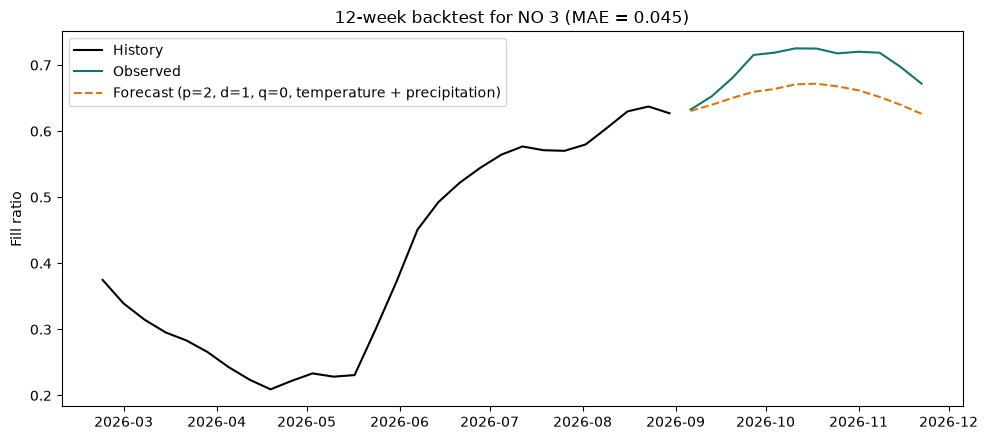

In [23]:
import matplotlib.pyplot as plt

fc, actual, mae = fc_mod.backtest(s, horizon=12, p=2, d=1, q=0, exog=exog_all)
history = s.iloc[-40:-12]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(history.index, history, color="black", label="History")
ax.plot(actual.index, actual, color="#0F766E", label="Observed")
ax.plot(fc.index, fc, color="#D97706", ls="--",
        label="Forecast (p=2, d=1, q=0, temperature + precipitation)")
ax.set_title(f"12-week backtest for NO 3 (MAE = {mae:.3f})")
ax.set_ylabel("Fill ratio")
ax.legend()
fig.tight_layout()
plt.show()

**Findings from the forecast tests.** The figure shows one backtest (the last 12 weeks, MAE = 0.045). The model follows the observed direction, but it underestimates the autumn rise in the fill ratio. The MAE values in the tables above (for example 0.035 with temperature and precipitation) are averages over three different forecast origins, so they are not directly comparable with the single backtest in the figure. In all tests the model with weather as exogenous variables was better than the model without, and a simple setting (p=2, d=1, q=0) beat the seasonal versions. The default in the Streamlit app is therefore p=2, d=1, q=0 with 260 weeks of history, learning rate 0.01, and temperature plus precipitation as exogenous variables.

In [21]:
f = s[s.index >= "2021-01-01"].rename("fill").reset_index()
f = f.rename(columns={f.columns[0]: "date"})
e = exog_all.reset_index()
e = e.rename(columns={e.columns[0]: "date"})
m = pd.merge_asof(f, e, on="date", direction="nearest", tolerance=pd.Timedelta("3D")).dropna()
m["fill_change"] = m["fill"].diff()

rows = []
for var in ["temperature", "precipitation"]:
    for target in ["fill", "fill_change"]:
        corrs = {k: m[var].shift(k).corr(m[target]) for k in range(0, 13)}
        best = max(corrs, key=lambda k: abs(corrs[k]))
        rows.append({"weather": var, "reservoir": target,
                     "corr lag 0": round(corrs[0], 2),
                     "best lag (weeks)": best, "corr at best lag": round(corrs[best], 2)})
print(pd.DataFrame(rows).to_string(index=False))

# Sliding window (12 weeks, lag 0): how much does the correlation vary?
for var in ["temperature", "precipitation"]:
    r = m[var].rolling(12).corr(m["fill"])
    print(var, "rolling corr with fill: min", round(r.min(), 2), "max", round(r.max(), 2))

      weather   reservoir  corr lag 0  best lag (weeks)  corr at best lag
  temperature        fill        0.26                11              0.77
  temperature fill_change        0.70                 0              0.70
precipitation        fill        0.19                 1              0.20
precipitation fill_change        0.25                 0              0.25
temperature rolling corr with fill: min -0.97 max 0.96
precipitation rolling corr with fill: min -0.76 max 0.86


## Structure sketch of the Streamlit app

![Structure sketch of the Streamlit app](structure_sketch.png)

The app is organised in groups: **Overview** (Home), **Explore** (Map, Reservoir data, ENTSO-E flows), **Analysis** (STL & spectrogram, Weather anomalies with SPC and LOF, Sliding window correlation), **Forecast** (River forecast) and **Info** (About). The area, year, weather property and time period selected on the map page are shared with the other pages through `st.session_state`.

## Project log (part 4)

**Notebook experience.** I developed the functions in the notebook first and then moved the reusable parts to modules (`forecasting.py`, `weather_utils.py`), so the notebook and the Streamlit pages run the same code. The Norges Bank function was straightforward. The time-zone investigation was the most useful part: it showed that the sources mix UTC timestamps and date-only values, so I keep hourly data in UTC and aggregate to dates before joining.

**Map and areas.** Magasinstatistikk has no official geometry for the four water areas (VASS 1-4). I built them by grouping the 306 catchment polygons by vassdragsnummer ranges that follow the NVE area descriptions. The border inside Rogaland between VASS 1 and VASS 2 is an assumption, because NVE only writes "parts of Rogaland". Weather on the map uses one representative point per area (ERA5 via open-meteo, daily values). This approximates an area average, but it keeps the number of API calls low.

**Sliding window correlation (NO 3, 2021-2026).** Temperature and the weekly change in fill ratio correlate at 0.70 with lag 0. Temperature and the fill ratio itself correlate at only 0.26 with lag 0, but 0.77 with a lag of 11 weeks. This is mostly the seasonal phase: warm periods come before full reservoirs, so it should not be read as direct causation. Precipitation is weak (at most 0.25). A 12-week window gives correlations between -0.97 and 0.96 for temperature, so the relationship depends strongly on the season and short windows are unstable.

**Forecasting.** I used River SNARIMAX on weekly data with a 12-week horizon, tested from three forecast origins. The best simple setting was p=2, d=1, q=0 (MAE 0.046), only slightly better than repeating the last value (0.049). Seasonal terms (m=52) did not help, probably because only about five years of history are used and the model is trained with SGD. A learning rate of 0.05 diverged. Adding temperature and precipitation as exogenous variables lowered the MAE to 0.035 (temperature alone: 0.041). Future weather is unknown, so the mean of the same week of the year is used, which is a simplification. The Streamlit default is p=2, d=1, q=0, 260 weeks of history, learning rate 0.01, and temperature plus precipitation.

**Bonus.** I implemented spinners with caching (`st.cache_data` for downloads) and error handling for failing APIs, rate limits and missing data (try/except with clear messages).

**Struggles.** The open-meteo rate limits forced me to batch and cache requests. River would not build on Windows until I upgraded pip so that a pre-built wheel was found. Moving shared code out of Streamlit made it usable in the notebook.

**Streamlit.** The menu is grouped, selections (area, year, weather property, period) are shared through `st.session_state`, and a click on the map changes the selection on the other pages. All figures are now Plotly, and the table and plot pages are merged into one page with tabs.

## AI usage

I used Claude (Anthropic) as an assistant while working on this part. I used it to discuss the design, to get suggestions for code structure (for example the River forecasting function and the Plotly animation), to understand and fix error messages, and to help phrase the text in this notebook. I ran all the code locally, tested the different settings myself, chose the defaults based on the results above, interpreted the findings, and checked that the app works on all pages.